# 01 · Which model should describe figures for a blind listener?

**Question.** hearxiv must turn each figure into a description that a blind researcher can *hear*.
Which vision model does this best, and what does it cost? We compare cloud APIs (OpenAI, Gemini free
tier) with open models that run **locally on a laptop CPU** (zero cost, fully private).

**Setup.**
* **18 standard seaborn / matplotlib figures** that look like ML papers: loss curves, model-comparison
  bars, confusion and attention heatmaps, violins, KDEs, regression, log-scale lines with CIs,
  multi-panel, facet grids, pair plots, clustermaps, ECDFs. Each is drawn from **seeded synthetic data**,
  so the answer key (title, axes, series, key numbers, trends) is known exactly from the plotting code
  (`benchmarks/figure_ocr/make_figures.py`).
* **One prompt for every model** (`hearxiv.vision.prompts`). It asks for the structure blind readers
  prefer (Lundgard & Satyanarayan 2021): overview, then axes, series, key numbers, pattern.
* **Two layers of scoring** (`benchmarks/figure_ocr/scoring.py`):
  1. *Automatic, no model bias:* chart type named, recall of title/axes/series (fuzzy match),
     and fact accuracy (numbers within tolerance, key phrases).
  2. *LLM judge* (`gpt-6.2-sol`, sees the image **and** the answer key): accuracy, completeness and
     listenability (0–5), plus a list of hallucinated claims.

**Hardware for local models:** AMD Ryzen 5 3500U (4 cores, 2019 laptop), 14 GB RAM, **no GPU**, float32.

In [1]:
import json, re, textwrap
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, HTML, Markdown
import sys

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
BENCH = ROOT / "benchmarks" / "figure_ocr"
sys.path.insert(0, str(BENCH))
from scoring import auto_score

GT = {g["id"]: g for g in json.loads((BENCH / "ground_truth.json").read_text(encoding="utf-8"))}
CLOUD, LOCAL = "#2a78d6", "#eb6834"  # categorical slots 1-2 (validated palette)
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "font.size": 10})
pd.set_option("display.max_colwidth", 200)
print(len(GT), "figures")

18 figures


## The figure suite

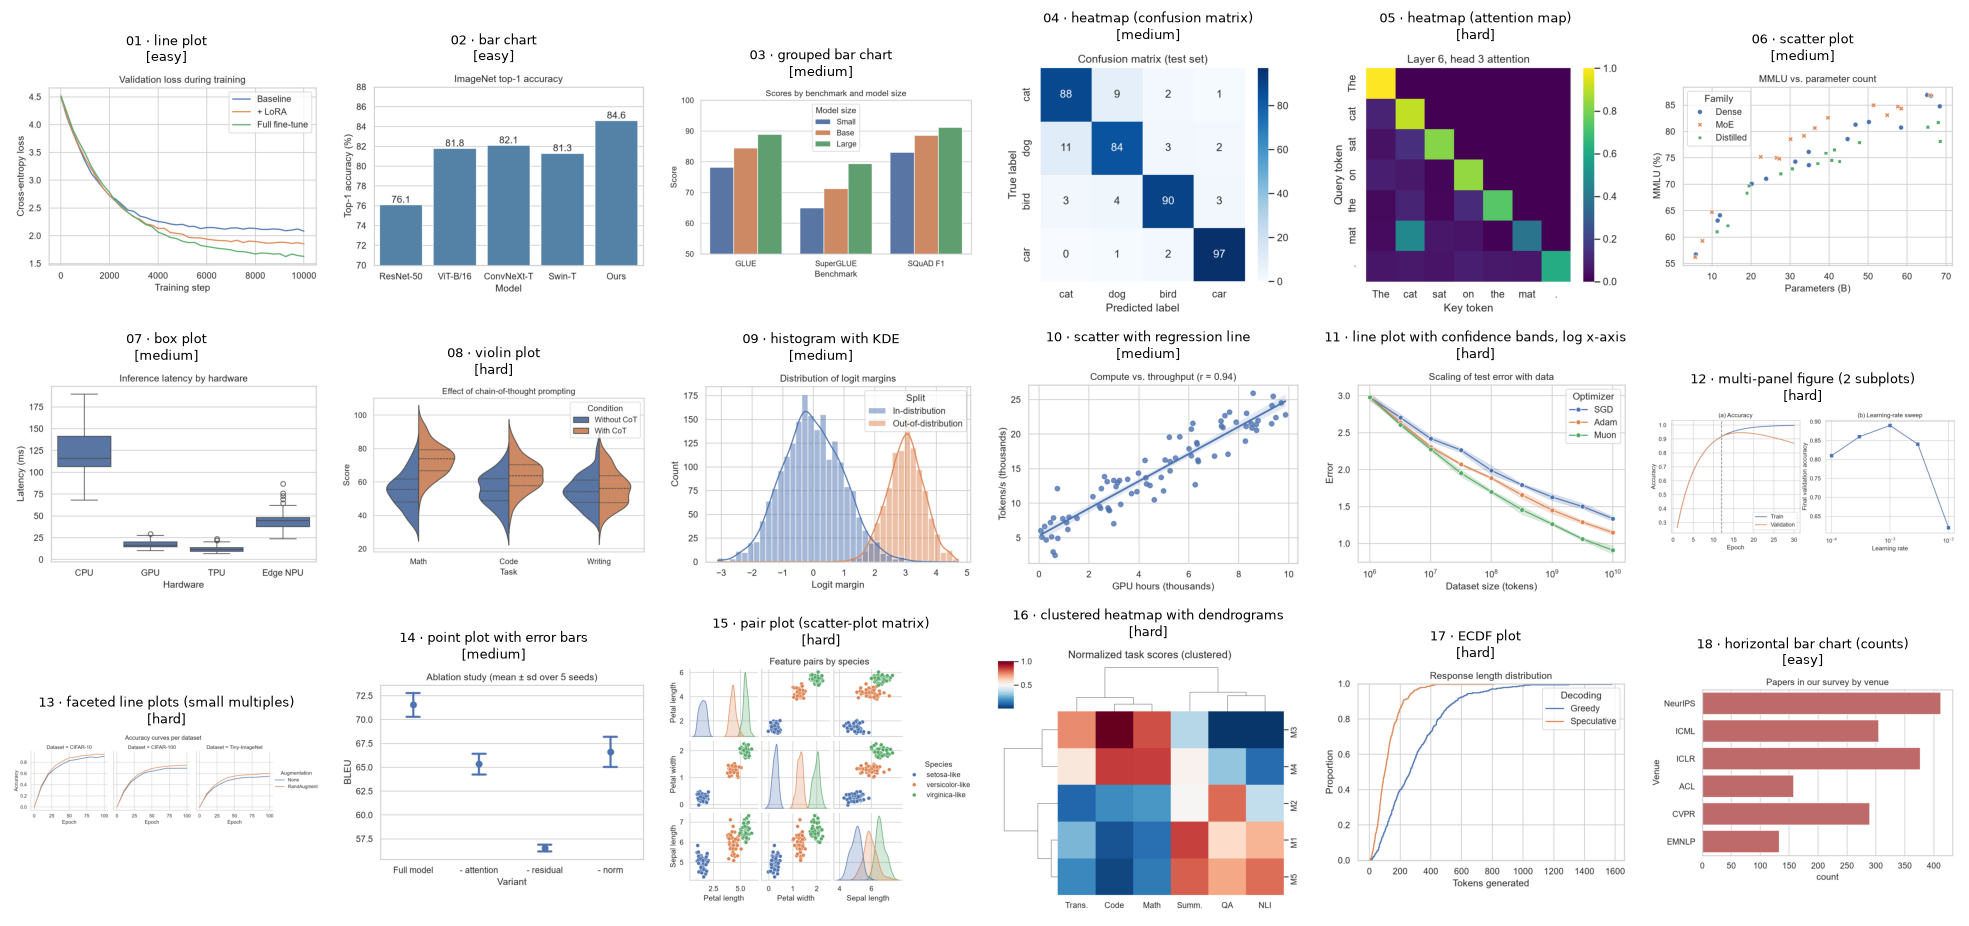

In [2]:
fig, axes = plt.subplots(3, 6, figsize=(18, 8.5))
for ax, (fid, g) in zip(axes.flat, GT.items()):
    ax.imshow(plt.imread(BENCH / g["file"])); ax.set_axis_off()
    ax.set_title(f"{fid[:2]} · {g['chart_type']}\n[{g['difficulty']}]", fontsize=8.5)
plt.tight_layout(); plt.show()

## Models tested

| Model | Where it runs | Size | Licence | Cost |
|---|---|---|---|---|
| `openai:gpt-6.2-astra` | OpenAI API | flagship | proprietary | $8 / $40 per 1M tokens (in / out) |
| `openai:gpt-6.1-terra` | OpenAI API | mid ("visual reasoning") | proprietary | $1 / $5 |
| `openai:gpt-6-luna` | OpenAI API | small | proprietary | $0.10 / $0.50 |
| `openai:gpt-5.4-mini` | OpenAI API | small, previous gen | proprietary | $0.75 / $4.50 |
| `gemini:gemini-3.8-flash` | Google API, **free tier** (≈20 req/day) | — | proprietary | $0 |
| `gemini:gemini-3.5-flash-lite` | Google API, **free tier** (≈500 req/day) | — | proprietary | $0 |
| `gemini:gemma-4-31b-it` | Google API (open-weights model) | 31B | Gemma (open) | $0 |
| `hf:Qwen/Qwen3.5-2B` | **local CPU** | 2B | Apache-2.0 | $0 |
| `hf:Qwen/Qwen3.5-0.8B` | **local CPU** | 0.8B | Apache-2.0 | $0 |
| `hf:HuggingFaceTB/SmolVLM-256M-Instruct` | **local CPU** (Docling's default describer) | 256M | Apache-2.0 | $0 |
| `hf:ibm-granite/granite-docling-258M` | **local CPU**, chart-to-table mode | 258M | Apache-2.0 | $0 |

*Not run here:* **IBM Granite Vision 4.1 (4B)** and **Gemma 4 E2B/E4B**. In float32 they need more than
14 GB RAM, and bfloat16 is emulated (very slow) on this CPU. Quantised GGUF via llama.cpp is the way to run
them on a laptop, but unsigned `llama.cpp` binaries are blocked by Windows Smart App Control on this machine.
They are the first thing to add on a machine with a GPU or with llama.cpp available (`local:` provider).

**Reproduce:**
```bash
uv run python benchmarks/figure_ocr/make_figures.py
uv run python benchmarks/figure_ocr/run_benchmark.py openai:gpt-6.1-terra gemini:gemini-3.5-flash-lite
uv run python benchmarks/figure_ocr/run_benchmark.py hf:Qwen/Qwen3.5-2B --max-side 768 --max-new-tokens 400
uv run python benchmarks/figure_ocr/judge_results.py
```

## Load results and score

In [3]:
rows = {}
for f in sorted((BENCH / "results").glob("*.jsonl")):
    if f.name == "judgments.jsonl":
        continue
    for line in f.read_text(encoding="utf-8").splitlines():
        r = json.loads(line)
        if r.get("text") is not None and not r.get("error"):
            rows[(r["model"], r["figure_id"])] = r
res = pd.DataFrame(rows.values())
auto = pd.DataFrame([auto_score(GT[r.figure_id], r.text) for r in res.itertuples()])
res = pd.concat([res.reset_index(drop=True), auto], axis=1)

judg = pd.DataFrame([json.loads(l) for l in (BENCH / "results" / "judgments.jsonl").read_text(encoding="utf-8").splitlines()])
judg = judg.drop_duplicates(["model", "figure_id"], keep="last")
res = res.merge(judg[["model", "figure_id", "accuracy", "completeness", "listenability", "n_hallucinations",
                      "hallucinations", "rationale"]], on=["model", "figure_id"], how="left")

res["local"] = res.model.str.startswith("hf:")
res["short"] = res.model.str.replace(r"^(openai|gemini|hf):", "", regex=True).str.replace(r"^.*/", "", regex=True)
# composite quality in [0, 1]: equal weight on automatic facts/labels and judged accuracy/completeness
res["quality"] = (res.fact_acc + res.label_recall + res.accuracy / 5 + res.completeness / 5) / 4
print(res.groupby("model").size().to_string())

model
gemini:gemini-3.5-flash-lite              18
hf:HuggingFaceTB/SmolVLM-256M-Instruct    13
openai:gpt-5.4-mini                       18
openai:gpt-6-luna                         18
openai:gpt-6.1-terra                      18
openai:gpt-6.2-astra                      18


### Cost per figure
OpenAI list prices × measured tokens. Gemini free tier and local models cost $0 (local costs electricity
and time instead).

In [4]:
PRICE = {"gpt-6.2-astra": (8, 40), "gpt-6.1-terra": (1, 5), "gpt-6-luna": (0.10, 0.50), "gpt-5.4-mini": (0.75, 4.50)}
def cost(r):
    p = PRICE.get(r.short)
    if not p or pd.isna(r.input_tokens):
        return 0.0
    return (r.input_tokens * p[0] + r.output_tokens * p[1]) / 1e6
res["usd"] = res.apply(cost, axis=1)

## Leaderboard

In [5]:
lb = (res.groupby(["model", "short", "local"])
        .agg(figures=("figure_id", "count"), quality=("quality", "mean"), fact_acc=("fact_acc", "mean"),
             label_recall=("label_recall", "mean"), type_hit=("type_hit", "mean"),
             judge_accuracy=("accuracy", "mean"), judge_completeness=("completeness", "mean"),
             judge_listenability=("listenability", "mean"), hallucinations_per_fig=("n_hallucinations", "mean"),
             sec_per_fig=("seconds", "median"), words=("words", "median"), usd_per_fig=("usd", "mean"))
        .reset_index().sort_values("quality", ascending=False))
lb["usd_per_1000_figs"] = lb.usd_per_fig * 1000
show = lb.drop(columns=["model", "usd_per_fig"]).set_index("short")
display(show.style.format({c: "{:.2f}" for c in show.columns if c not in ("figures", "local", "words")} |
                          {"usd_per_1000_figs": "${:.2f}", "sec_per_fig": "{:.1f}s", "words": "{:.0f}"})
            .background_gradient(cmap=BLUES, subset=["quality", "fact_acc", "judge_accuracy", "judge_completeness"]))

,local,figures,quality,fact_acc,label_recall,type_hit,judge_accuracy,judge_completeness,judge_listenability,hallucinations_per_fig,sec_per_fig,words,usd_per_1000_figs
short,,,,,,,,,,,,,
gpt-6.1-terra,False,18,0.93,0.97,0.87,0.94,4.78,4.56,4.67,0.22,8.4s,162,$3.09
gpt-6-luna,False,18,0.89,0.93,0.84,1.00,4.33,4.56,4.50,1.00,5.3s,178,$0.36
gpt-6.2-astra,False,18,0.89,0.84,0.78,1.00,4.89,4.72,4.72,0.11,6.9s,204,$18.09
gpt-5.4-mini,False,18,0.86,0.90,0.86,1.00,4.06,4.28,4.06,1.78,3.4s,228,$2.22
gemini-3.5-flash-lite,False,18,0.82,0.74,0.89,1.00,3.67,4.67,4.56,2.17,2.0s,200,$0.00
SmolVLM-256M-Instruct,True,13,0.31,0.10,0.43,0.15,3.00,0.89,1.56,1.89,61.1s,5,$0.00


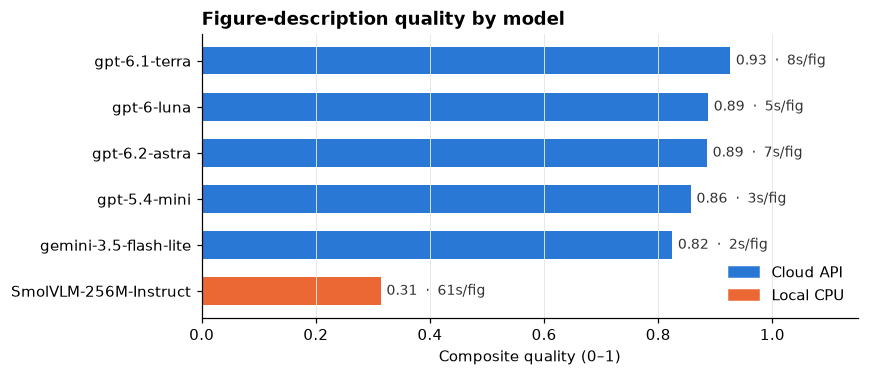

In [6]:
fig, ax = plt.subplots(figsize=(8, 0.42 * len(lb) + 1))
lbs = lb.sort_values("quality")
ax.barh(lbs.short, lbs.quality, color=[LOCAL if l else CLOUD for l in lbs.local], height=0.6)
for y, (q, s) in enumerate(zip(lbs.quality, lbs.sec_per_fig)):
    ax.text(q + 0.01, y, f"{q:.2f}  ·  {s:.0f}s/fig", va="center", fontsize=9, color="#333")
ax.set_xlim(0, 1.15); ax.set_xlabel("Composite quality (0–1)"); ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=CLOUD), plt.Rectangle((0, 0), 1, 1, color=LOCAL)],
          labels=["Cloud API", "Local CPU"], loc="lower right", frameon=False)
ax.set_title("Figure-description quality by model", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

## Quality vs. latency

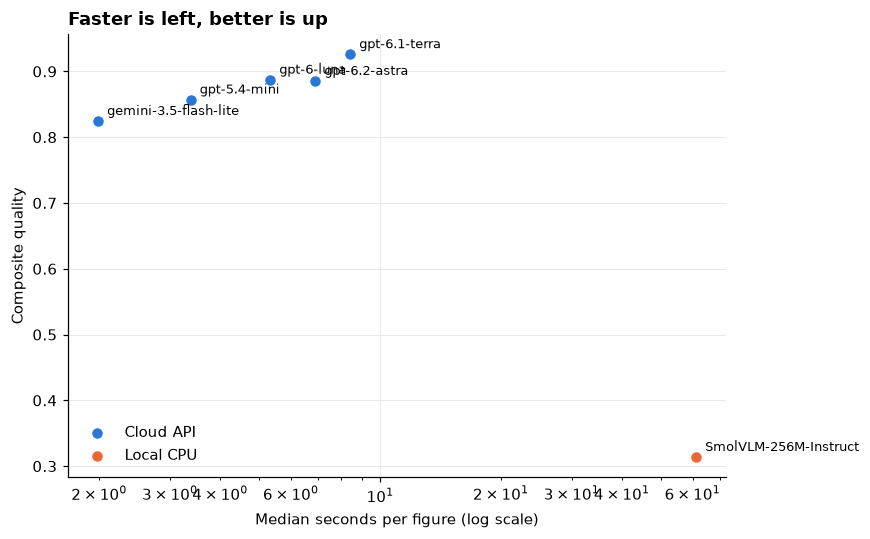

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
for loc, col, lab in [(False, CLOUD, "Cloud API"), (True, LOCAL, "Local CPU")]:
    d = lb[lb.local == loc]
    ax.scatter(d.sec_per_fig, d.quality, s=70, color=col, label=lab, edgecolor="white", linewidth=1.5, zorder=3)
    for r in d.itertuples():
        ax.annotate(r.short, (r.sec_per_fig, r.quality), xytext=(6, 4), textcoords="offset points", fontsize=8.5)
ax.set_xscale("log"); ax.set_xlabel("Median seconds per figure (log scale)"); ax.set_ylabel("Composite quality")
ax.legend(frameon=False, loc="lower left"); ax.set_title("Faster is left, better is up", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

## Where models fail: quality per figure

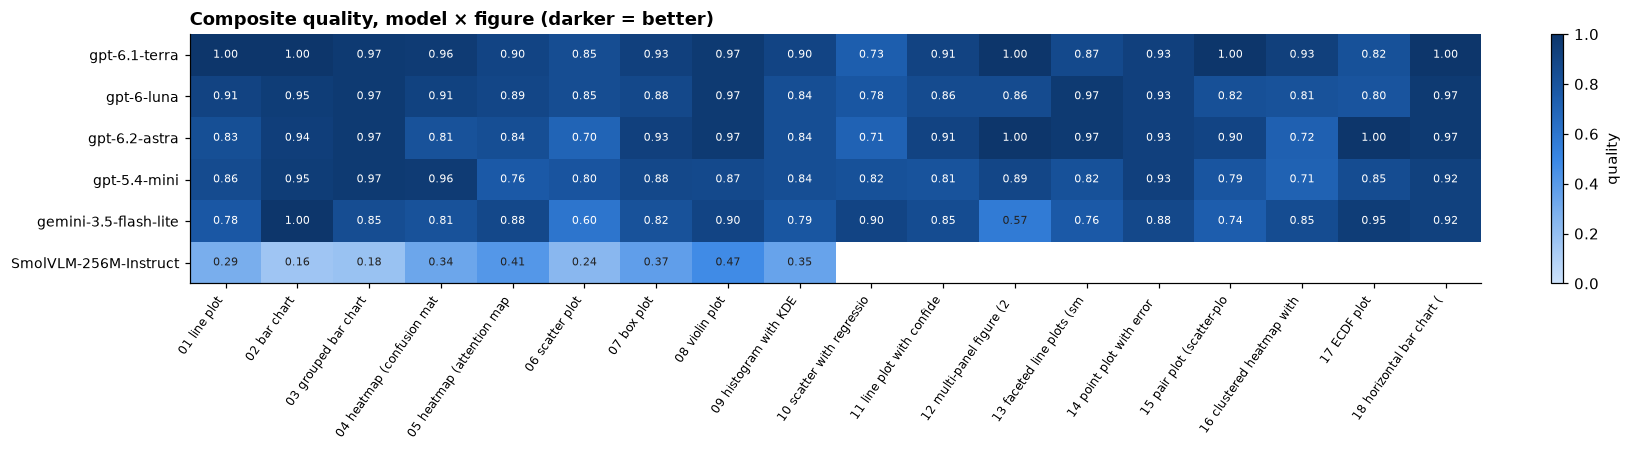

In [8]:
order_models = lb.short.tolist()
piv = res.pivot_table(index="short", columns="figure_id", values="quality").reindex(order_models)
fig, ax = plt.subplots(figsize=(15, 0.45 * len(piv) + 1.5))
im = ax.imshow(piv.values, cmap=BLUES, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(piv.shape[1]), [c[:2] + " " + GT[c]["chart_type"][:22] for c in piv.columns], rotation=55, ha="right", fontsize=8)
ax.set_yticks(range(piv.shape[0]), piv.index, fontsize=9); ax.grid(False)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 0.6 else "#222")
fig.colorbar(im, ax=ax, fraction=0.02, label="quality")
ax.set_title("Composite quality, model × figure (darker = better)", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

In [9]:
by_diff = res.pivot_table(index="short", columns=res.figure_id.map(lambda f: GT[f]["difficulty"]),
                          values="quality").reindex(order_models)[["easy", "medium", "hard"]]
display(by_diff.style.format("{:.2f}").background_gradient(cmap=BLUES, vmin=0, vmax=1))

figure_id,easy,medium,hard
short,,,
gpt-6.1-terra,1.00,0.90,0.92
gpt-6-luna,0.94,0.88,0.87
gpt-6.2-astra,0.91,0.84,0.91
gpt-5.4-mini,0.91,0.88,0.81
gemini-3.5-flash-lite,0.90,0.81,0.81
SmolVLM-256M-Instruct,0.23,0.30,0.44


## The description table
For every figure, each model's description and its scores (A = judge accuracy, C = completeness,
facts = automatic fact accuracy). This is the qualitative heart of the benchmark: read a few rows.


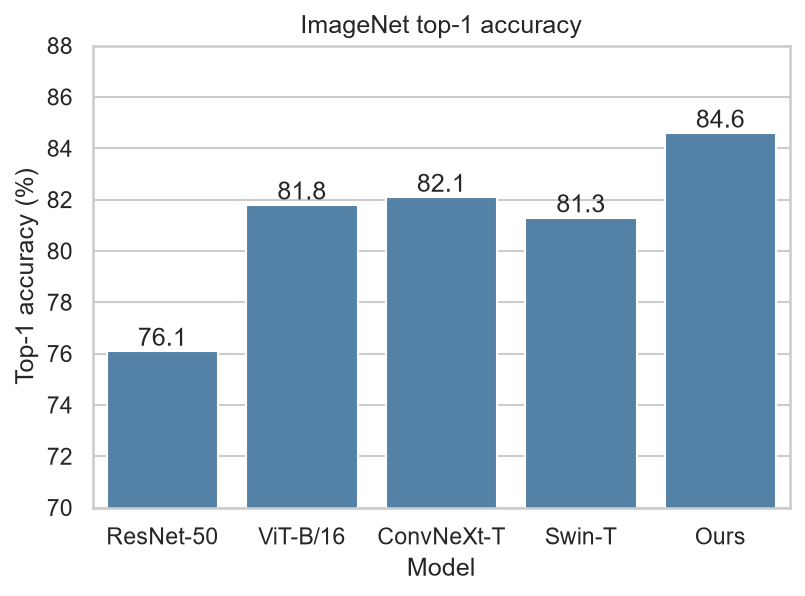


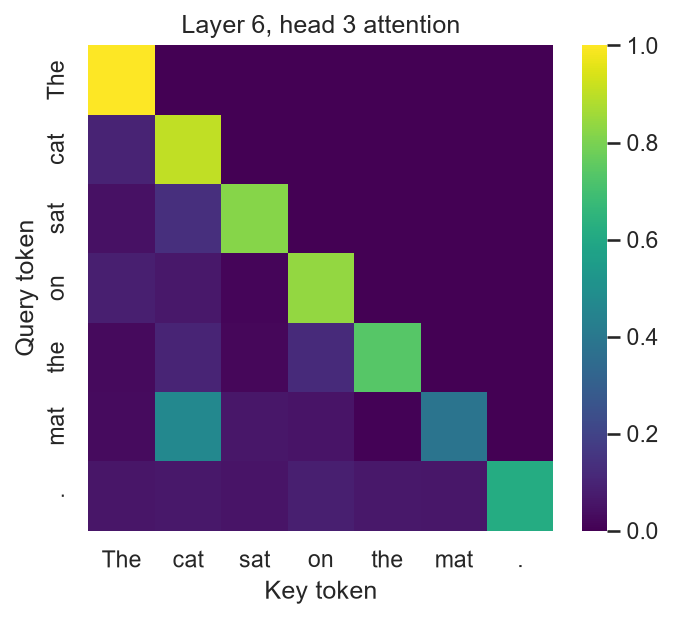


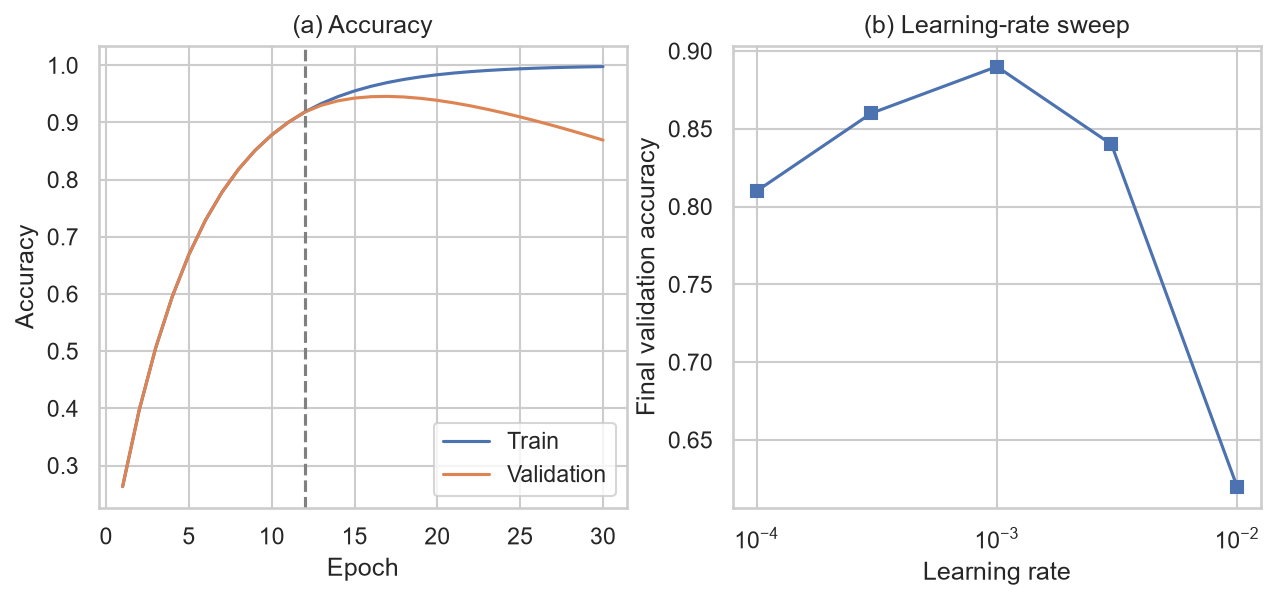


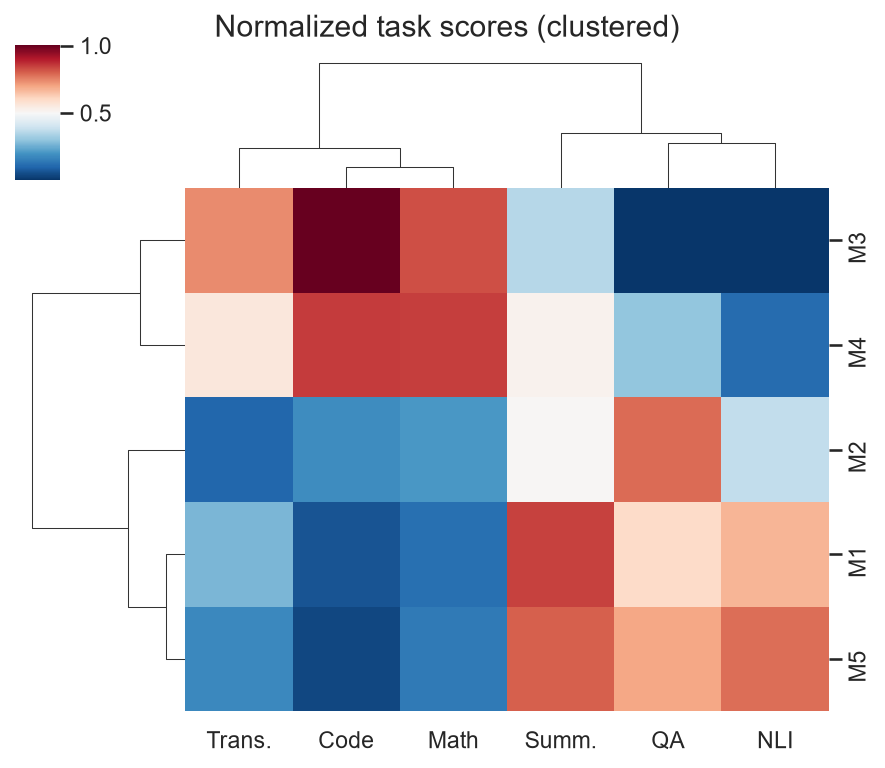

In [10]:
import base64, html
def thumb(path, w=260):
    return f'<img src="data:image/png;base64,{base64.b64encode(Path(path).read_bytes()).decode()}" width="{w}">'

def figure_table(fid):
    d = res[res.figure_id == fid].set_index("short").reindex([m for m in order_models if m in set(res[res.figure_id == fid].short)])
    cells = "".join(
        f"<tr><td style='vertical-align:top;white-space:nowrap'><b>{m}</b><br>A {r.accuracy:.0f} · C {r.completeness:.0f}"
        f"<br>facts {r.fact_acc:.2f}<br>{r.seconds:.0f}s</td>"
        f"<td style='vertical-align:top;text-align:left;font-size:12px'>{html.escape(r.text)}"
        + (f"<br><span style='color:#b3261e'>✗ {html.escape('; '.join(r.hallucinations))}</span>"
           if isinstance(r.hallucinations, list) and r.hallucinations else "")
        + "</td></tr>" for m, r in d.iterrows())
    g = GT[fid]
    return (f"<h4>{fid} · {g['chart_type']} [{g['difficulty']}]</h4><table><tr><td colspan=2>{thumb(BENCH / g['file'])}</td></tr>"
            f"{cells}</table>")

for fid in ["02_bar_benchmark_accuracy", "05_heatmap_attention_unannotated", "12_multi_panel_subplots", "16_clustermap"]:
    display(HTML(figure_table(fid)))

In [11]:
# Full side-by-side table (all figures x all models) exported for browsing on GitHub
lines = ["# Figure descriptions by model\n", "Generated by notebooks/01_figure_description_benchmark.ipynb.\n"]
for fid, g in GT.items():
    lines.append(f"\n## {fid} · {g['chart_type']} [{g['difficulty']}]\n\n![{fid}](figures/{fid}.png)\n")
    lines.append("| model | judge acc / compl | facts | description |\n|---|---|---|---|")
    for m in order_models:
        r = res[(res.figure_id == fid) & (res.short == m)]
        if r.empty:
            continue
        r = r.iloc[0]
        txt = r.text.replace("\n", " ").replace("|", "\\|")
        lines.append(f"| {m} | {r.accuracy:.0f} / {r.completeness:.0f} | {r.fact_acc:.2f} | {txt} |")
(BENCH / "DESCRIPTIONS.md").write_text("\n".join(lines), encoding="utf-8")
print("wrote", BENCH / "DESCRIPTIONS.md")

wrote D:\Root\Repositories\Personal\hearxiv\benchmarks\figure_ocr\DESCRIPTIONS.md


## Failure analysis: what goes wrong?

In [12]:
from collections import Counter
miss = Counter(f for fs in res.missed_facts for f in fs)
display(pd.DataFrame(miss.most_common(15), columns=["fact most often missed (all models)", "models missing it"]))
worst = res.sort_values("quality").head(8)[["short", "figure_id", "quality", "rationale"]]
display(worst)

,fact most often missed (all models),models missing it
0,diminishing returns / log-like curve,6
1,OOD narrower / fewer samples,5
2,shaded bands show variability across seeds,4
3,panel (b) best learning rate 1e-3,4
4,starting loss about 4.5,3
5,full fine-tune final loss about 1.62,3
6,x axis runs to 10000 steps,3
7,car correctly classified 97,3
8,cat correct 88,3
9,dog predicted as cat 11,3


,short,figure_id,quality,rationale
19,SmolVLM-256M-Instruct,02_bar_benchmark_accuracy,0.162500,"The sentence correctly identifies the metric, but 88% is the top y-axis tick, not a model's accuracy; Ours leads at 84.6%. It is easy to hear but too terse to convey the bar chart, its five models..."
20,SmolVLM-256M-Instruct,03_grouped_bar_hue,0.183333,"The description correctly names only SQuAD F1 and omits the grouped bar chart structure, axes, model sizes, key scores, and the main patterns: larger models score higher on every benchmark, and Su..."
23,SmolVLM-256M-Instruct,06_scatter_hue,0.241667,"The description correctly mentions parameter count, but it is too terse to orient a listener. It omits the scatter plot format, axis units, all three model families, the maximum of about 70 billio..."
18,SmolVLM-256M-Instruct,01_line_loss_curves,0.291667,"The description states the title correctly but omits the plot type, axes, three series, key values, and the overall decline in loss. The title is clear when read aloud, but it is too terse to serv..."
21,SmolVLM-256M-Instruct,04_heatmap_confusion_annotated,0.335714,"The description states the exact title and correctly identifies the confusion matrix, but it is too terse to serve as a spoken figure description. It omits the axes, the four classes, the key coun..."
26,SmolVLM-256M-Instruct,09_hist_kde,0.350000,"The phrase is easy to hear but too terse to explain the figure, and it misnames the plotted quantity. It omits the histograms and density curves, the axis labels, and the two groups: in-distributi..."
24,SmolVLM-256M-Instruct,07_box_latency,0.371429,"The description correctly states the title and is clear when read aloud, but it is too terse to describe the figure. It omits the box-plot format, the axes and units, all four hardware categories,..."
22,SmolVLM-256M-Instruct,05_heatmap_attention_unannotated,0.412500,"The description correctly hints that 'sat' attends to itself, but it omits the heatmap overview, axis labels, full token sequence, causal mask, strong diagonal, and zero-to-one color scale. Repeat..."


## Conclusions
*(written after running; see the summary at the top of `benchmarks/figure_ocr/README.md`)*

<!-- CONCLUSIONS -->